In [1]:
import time
import cv2
import math
from itertools import compress,product
from skimage.io import imread, imshow
from skimage.transform import resize
import skimage.io as io
from skimage import data, color, io
from skimage.util.shape import view_as_windows
from typing import Tuple

# get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
plt.style.use('seaborn-white')
plt.switch_backend('agg')
import numpy as np  
import pandas as pd
import glob
import matplotlib.image as mpimg

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.datasets as dsets
from torchsummary import summary
from torch.autograd import Variable
# import lovasz_losses as L

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random
import os
from os import listdir
from os.path import isfile, join
from os import walk
from sklearn.model_selection import train_test_split
from sklearn.metrics import jaccard_similarity_score

from albumentations import (
    HorizontalFlip, VerticalFlip, CLAHE,
    ShiftScaleRotate, OpticalDistortion, GridDistortion, ElasticTransform, HueSaturationValue,
    RandomBrightnessContrast, IAAPiecewiseAffine,
    IAASharpen, IAAEmboss, Flip, OneOf, Compose, IAASuperpixels

)

import warnings
warnings.filterwarnings("ignore")


In [2]:
def load_pathnames_filenames(path): # read and store all file names in order
    for (_, dirnames, _) in walk(path):
        print("dirnames", dirnames)
        break

    label_path = join(path, dirnames[0])
    seismics_path = join(path, dirnames[1])

    for (_, _, filenames) in walk(label_path):
        labels = sorted(filenames)
    for (_, _, filenames) in walk(seismics_path):
        seismics = sorted(filenames)

    print("number of images in two folder: ",len(labels),len(seismics))
#     print("label_path: ", label_path)
#     print("seismics_path: ", seismics_path)

    print(labels[0])
    print(seismics[0])

    return label_path, seismics_path, labels, seismics

In [3]:
img_path = 'screenshots'
label_path, seismics_path, labels, seismics = load_pathnames_filenames(img_path)

dirnames ['label', 'seismic']
number of images in two folder:  1807 1807
Interpretation window 3 Friday, 06 September 2019 14_47_34.png
Interpretation window 3 Friday, 06 September 2019 11_03_43.png


In [4]:
t_start = time.time()
faults = np.zeros((1803,1537,3174), dtype=np.bool)
for i in range(4,len(labels)): # we delete the first 4 crosslines as there is no fault annotations on them.
    mask = cv2.imread(join(label_path,labels[i]))
    mask = cv2.cvtColor(mask, cv2.COLOR_BGR2GRAY) # ignore color different as they all belong to one class fault
    mask = mask[106:-26,84:-34] # remove axis boarders
    mask = cv2.resize(mask,(3174,1537)) # resize them into seismic volume shape.
    mask = mask<255 # make it binary
    mask = np.fliplr(mask) # horizontal flip to make the direction the same as seismic volume.
    faults[i-4] = mask
print("read images in {} sec".format(time.time()-t_start))   

read images in 71.1986632347107 sec


check fault annotations

In [5]:
print(faults.shape)

(1803, 1537, 3174)


<function matplotlib.pyplot.show(*args, **kw)>

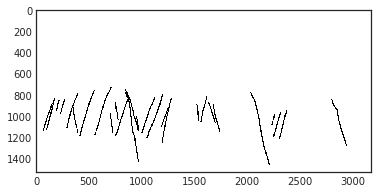

In [6]:
plt.figure()
plt.imshow(faults[1500])
plt.show

save the processed fault annotations in one file or train,val,test set

In [7]:
# np.save("faults.npy",faults)

# or

# np.save("faulttrain.npy",fault[:900])
# np.save("faultval.npy",fault[900:1100])
# np.save("faulttest.npy",fault[1100:])

# Explaination about each process step

In [8]:
img = cv2.imread(join(seismics_path,seismics[6]))
mask = cv2.imread(join(label_path,labels[6]))
print(img.shape)
print(mask.shape)

(825, 1405, 3)
(825, 1405, 3)


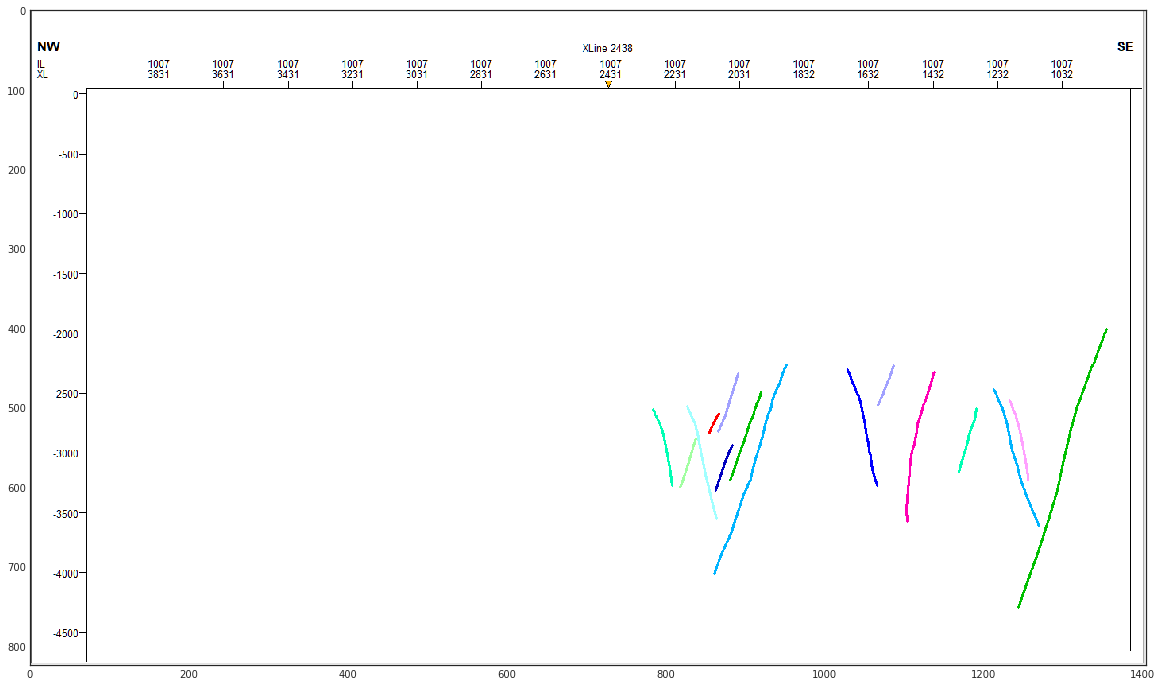

In [9]:
# plt.figure(figsize=(20,16))
# plt.imshow(img)
# plt.show()
plt.figure(figsize=(20,16))
plt.imshow(mask)
plt.show()

check vertical axis boarder pixels

In [10]:
imgt = img[:,190,2]
print(imgt.shape)

(825,)


In [11]:
print(imgt.tolist())

[160, 105, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 0, 255, 255, 255, 255, 255, 255, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 2

In [12]:
array = [160, 105, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 0, 255, 255, 255, 255, 255, 255]
print(len(array))

106


Check horizontal boarder pixels

In [13]:
print(img[300].transpose()) # 3 channel (RGB) image 

[[160 105 255 ... 171 227 255]
 [160 105 255 ... 171 227 255]
 [160 105 255 ... 171 227 255]]


In [14]:
imgt = img[600].transpose()
print(imgt[1].tolist())

[160, 105, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 0, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 203, 2

In [15]:
array = [255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 0, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 171, 171, 227, 255]
print(len(array))

33


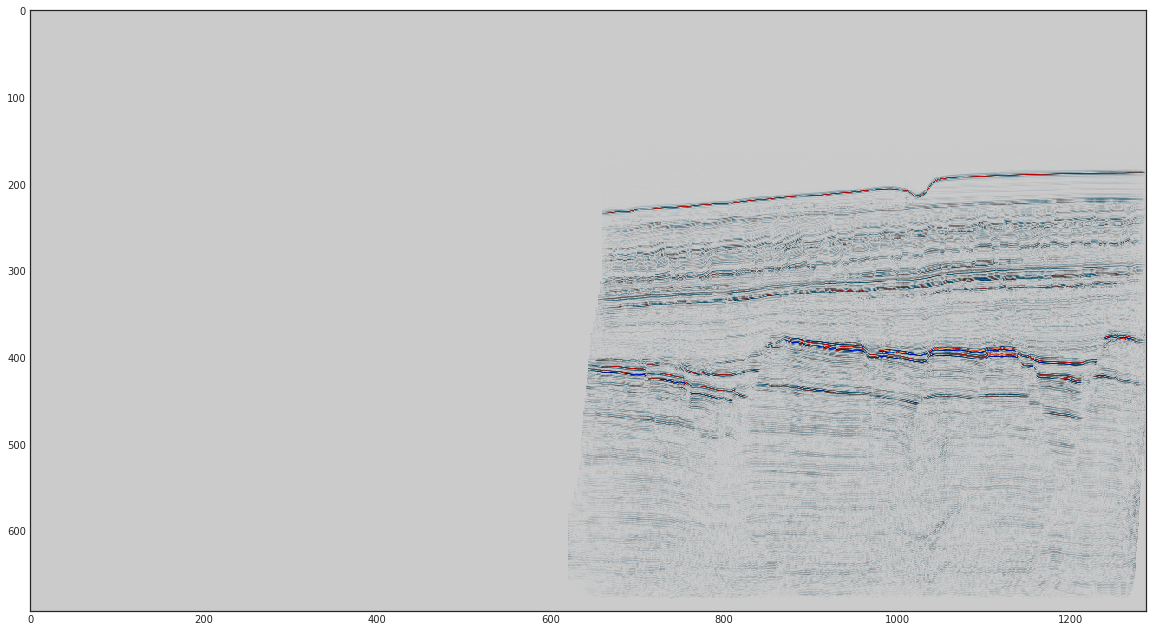

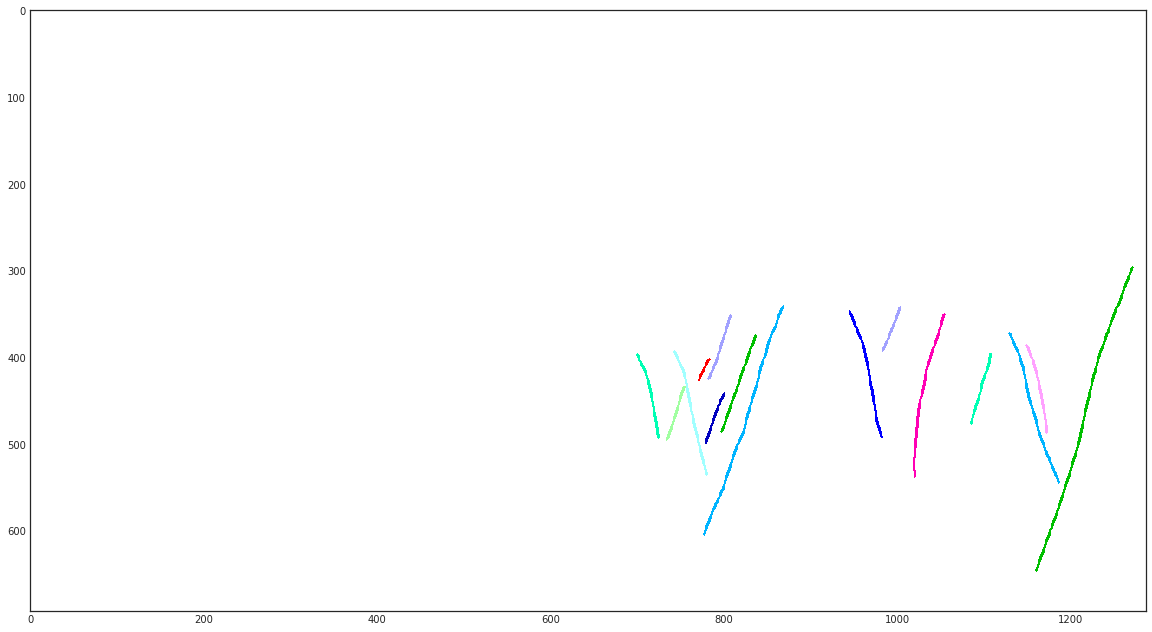

In [16]:
plt.figure(figsize=(20,16))
plt.imshow(img[106:-26,84:-34,:])
plt.show()
plt.figure(figsize=(20,16))
plt.imshow(mask[106:-26,84:-34,:])
plt.show()

In [17]:
mask1 = mask[106:-26,84:-34,:]
mask2 = cv2.resize(mask1,(3174,1537)) # scale it to seismic volume crossline shape
print(mask1.shape, mask2.shape)

(693, 1287, 3) (1537, 3174, 3)


In [18]:
maskgray = cv2.cvtColor(mask1, cv2.COLOR_BGR2GRAY)
print(maskgray.shape)

(693, 1287)


In [19]:
print(maskgray.max(), maskgray.min())

255 29


In [20]:
print((maskgray[300]<255).tolist())

[False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False

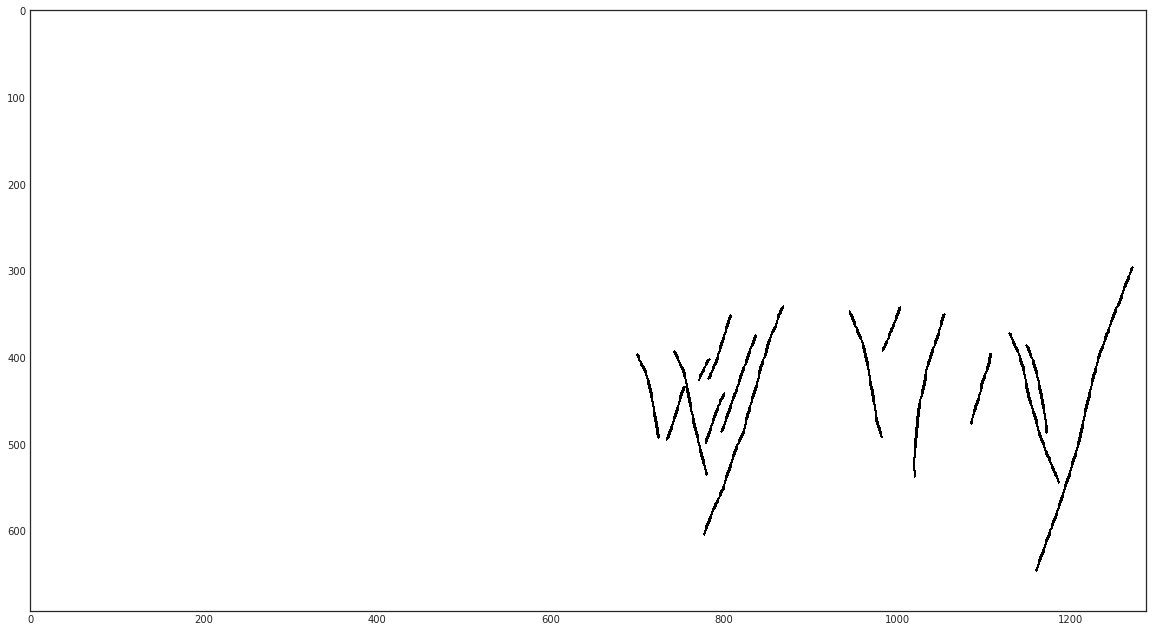

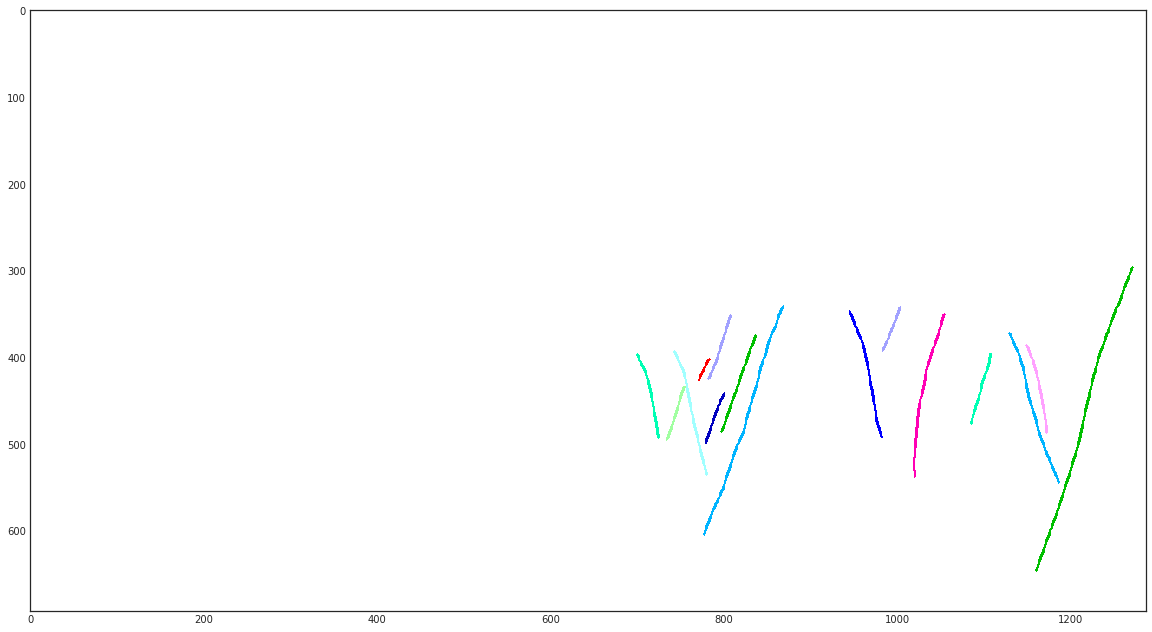

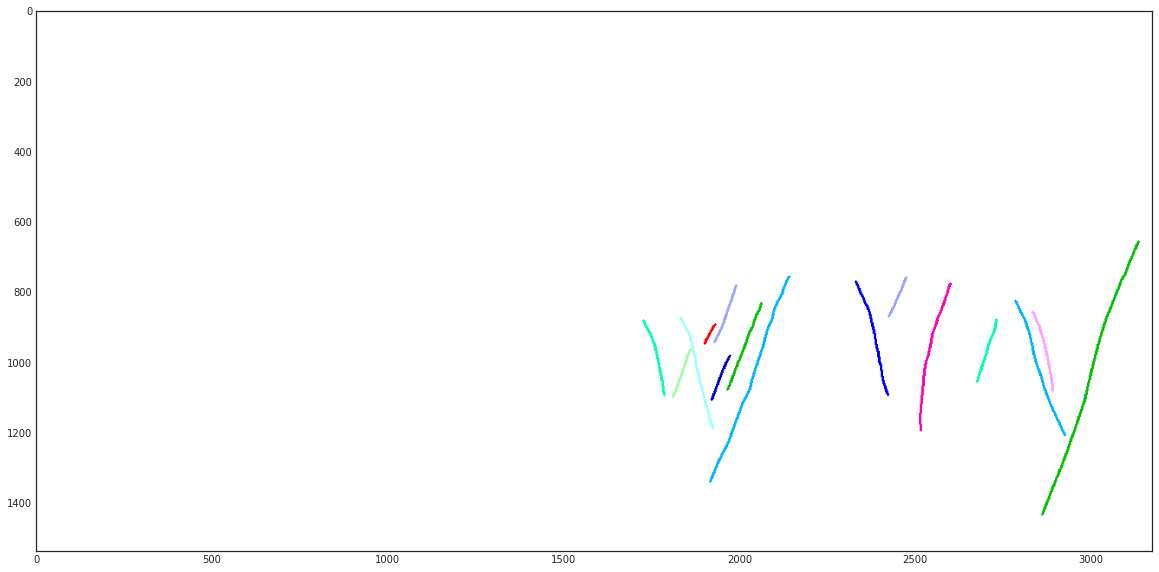

In [21]:
plt.figure(figsize=(20,16))
plt.imshow(maskgray<255)
plt.show()
plt.figure(figsize=(20,16))
plt.imshow(mask1)
plt.show()
plt.figure(figsize=(20,16))
plt.imshow(mask2)
plt.show()

In [27]:
data_folder "..<data folder>.."
seis_path = '{}/thebeorigin/seistrain.npy'.format(data_folder)
seis = np.load(seis_path)

In [28]:
IL, XL, Z = seis.shape
print(IL, XL, Z)

900 3174 1537


In [33]:
print(seis.max(), seis.min())

9.433253288269043 -8.393916130065918


In [35]:
a = img[106:-26,84:-34,:]
b = seis[0].transpose()
print(a.shape, a.max(), a.dtype)
print(b.shape, b.max(), b.dtype)

(693, 1287, 3) 245 uint8
(1537, 3174) 1.9348697662353516 float64


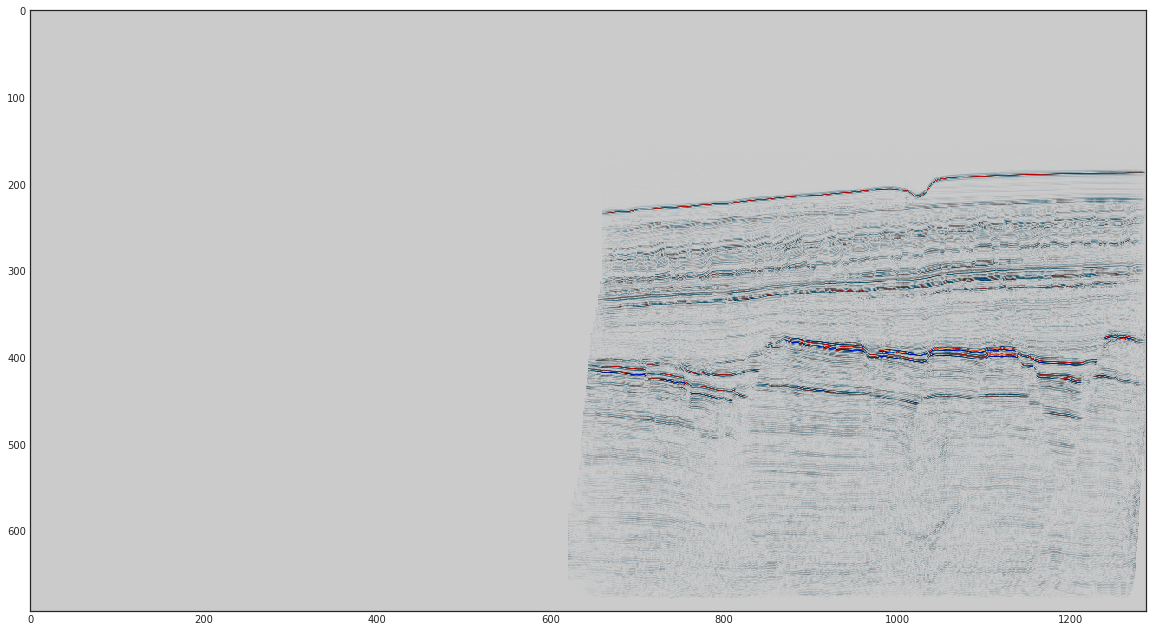

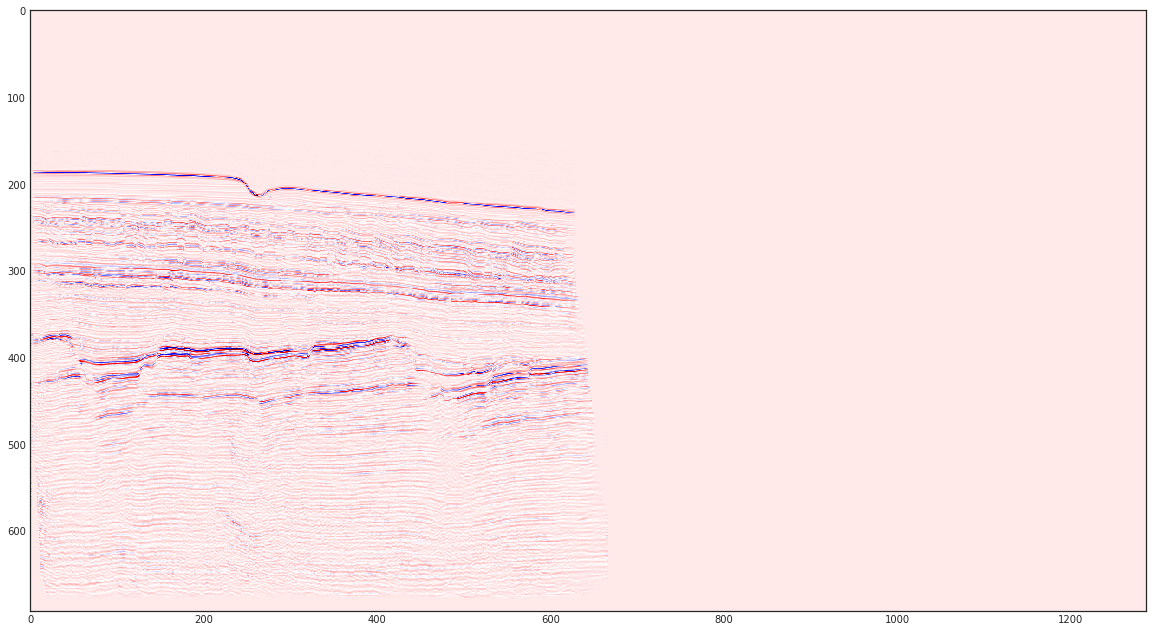

In [32]:
plt.figure(figsize=(20,16))
plt.imshow(a,cmap='seismic')
plt.show()
plt.figure(figsize=(20,16))
plt.imshow(b,cmap='seismic')
plt.show()

# result show that a horizontal flip is needed